<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS09/lab3_js09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah 1 – Instal Library
Instal `hnswlib` untuk membangun indeks HNSW. Scikit-learn digunakan untuk metode Exact NN.

In [1]:
!pip install -q hnswlib scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Langkah 2 – Import Library
Import `hnswlib`, NumPy, `time`, serta `NearestNeighbors` dari Scikit-learn.

In [2]:
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

## Langkah 3 – Membuat Dataset Dummy
Buat 1.000 titik data acak dengan dua dimensi. Query point ditetapkan pada koordinat `[0.5, 0.5]`, kemudian tentukan jumlah tetangga sebanyak 5.

In [3]:
# Build Dummy Dataset
num_elements = 1000
dim = 2
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # cari 5 tetangga terdekat

print('Jumlah data:', num_elements)
print('Dimensi:', dim)
print('Query point:', query)
print('Jumlah tetangga:', k)

Jumlah data: 1000
Dimensi: 2
Query point: [[0.5 0.5]]
Jumlah tetangga: 5


## Langkah 4 – Membuat Model Exact NN
Metode Exact NN menggunakan `NearestNeighbors` dengan `algorithm='brute'` dan metrik Euclidean. Model dilatih menggunakan dataset, kemudian menghitung 5 tetangga terdekat dari query point. Waktu yang diukur adalah waktu pencarian setelah model di-fit.

In [4]:
# Build NN Model
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

# Compute time performance
start = time.time()
distances_exact, indices_exact = nn.kneighbors(query)
end = time.time()
time_exact = end - start

print('=== Exact NN ===')
print('Indices:', indices_exact)
print('Distances:', distances_exact)
print('Waktu:', time_exact, 's')

=== Exact NN ===
Indices: [[536 230 133 607 268]]
Distances: [[0.01607135 0.02568987 0.02633767 0.02649541 0.02870267]]
Waktu: 0.03251934051513672 s


## Langkah 5 – Membuat Model HNSW
HNSW membangun indeks berbasis hierarchical navigable small-world graph. Parameter `ef_construction` dan `M` digunakan saat membangun indeks, sedangkan `ef` mengatur pencarian dengan trade-off antara kecepatan dan kualitas hasil.

Perhatikan bahwa `hnswlib` dengan `space='l2'` mengembalikan **kuadrat jarak Euclidean**, bukan jarak Euclidean biasa.

In [5]:
# Initiate Index
p = hnswlib.Index(space='l2', dim=dim)

# Define Max Elements and HNSW parameters
p.init_index(max_elements=num_elements, ef_construction=100, M=16)

# Add Data
p.add_items(data)

# Set searching parameter
p.set_ef(50)  # tradeoff speed vs accuracy

# Search and compute time performance
start = time.time()
labels_hnsw, distances_hnsw = p.knn_query(query, k=k)
end = time.time()
time_hnsw = end - start

print('=== HNSW ===')
print('Indices:', labels_hnsw)
print('Distances (squared L2):', distances_hnsw)
print('Waktu:', time_hnsw, 's')

=== HNSW ===
Indices: [[536 230 133 607 268]]
Distances (squared L2): [[0.00025829 0.00065997 0.00069367 0.00070201 0.00082384]]
Waktu: 0.00017595291137695312 s


## Langkah 6 – Membandingkan Hasil Exact NN dan HNSW
Bandingkan indeks tetangga dan waktu pencarian. Untuk membandingkan jarak secara adil, ubah squared L2 dari HNSW menjadi jarak Euclidean dengan mengambil akar kuadrat. Perhatikan bahwa waktu eksekusi sangat singkat sehingga dapat dipengaruhi overhead dan variasi sistem.

In [6]:
# Convert HNSW squared L2 distances to Euclidean distances
distances_hnsw_euclidean = np.sqrt(distances_hnsw)

print('=== PERFORMANCE COMPARISON ===')
print('Exact NN indices :', indices_exact)
print('HNSW indices     :', labels_hnsw)
print('Exact NN distances (Euclidean):', distances_exact)
print('HNSW distances (Euclidean):', distances_hnsw_euclidean)
print('Exact NN search time:', time_exact, 's')
print('HNSW search time    :', time_hnsw, 's')

exact_set = set(indices_exact[0].tolist())
hnsw_set = set(labels_hnsw[0].tolist())
overlap = len(exact_set.intersection(hnsw_set))
recall_at_k = overlap / k
print(f'Jumlah tetangga yang sama: {overlap} dari {k}')
print(f'Recall@{k}: {recall_at_k:.2f}')

if time_hnsw > 0:
    print('Rasio waktu Exact NN / HNSW:', time_exact / time_hnsw)

=== PERFORMANCE COMPARISON ===
Exact NN indices : [[536 230 133 607 268]]
HNSW indices     : [[536 230 133 607 268]]
Exact NN distances (Euclidean): [[0.01607135 0.02568987 0.02633767 0.02649541 0.02870267]]
HNSW distances (Euclidean): [[0.01607135 0.02568987 0.02633767 0.02649541 0.02870267]]
Exact NN search time: 0.03251934051513672 s
HNSW search time    : 0.00017595291137695312 s
Jumlah tetangga yang sama: 5 dari 5
Recall@5: 1.00
Rasio waktu Exact NN / HNSW: 184.81842818428186


## Langkah 7 – Visualisasi Hasil
Grafik menampilkan seluruh titik dataset, query point, lima tetangga hasil Exact NN, dan lima tetangga hasil HNSW. Titik yang sama dari kedua metode dapat saling bertumpuk.

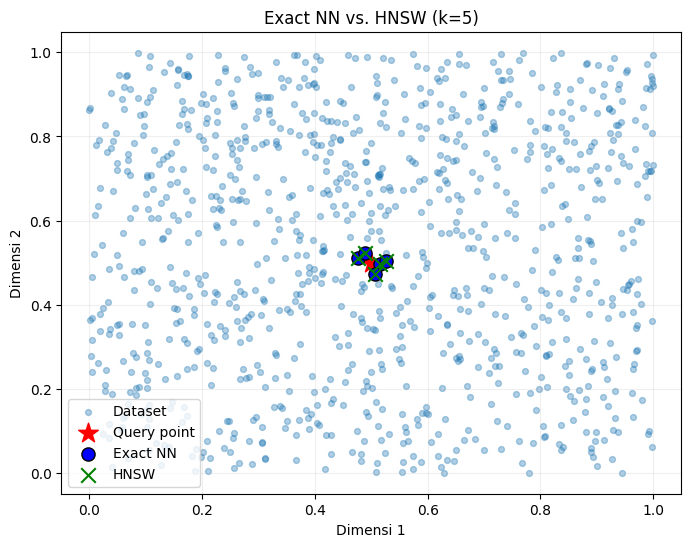

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(data[:, 0], data[:, 1], s=18, alpha=0.35, label='Dataset')
plt.scatter(query[0, 0], query[0, 1], c='red', marker='*', s=220, label='Query point')
plt.scatter(data[indices_exact[0], 0], data[indices_exact[0], 1],
            c='blue', marker='o', s=90, edgecolors='black', label='Exact NN')
plt.scatter(data[labels_hnsw[0], 0], data[labels_hnsw[0], 1],
            c='green', marker='x', s=110, label='HNSW')
plt.title('Exact NN vs. HNSW (k=5)')
plt.xlabel('Dimensi 1')
plt.ylabel('Dimensi 2')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## Analisis dan Kesimpulan
Exact NN memeriksa seluruh data untuk memperoleh hasil tetangga terdekat yang tepat. HNSW memanfaatkan struktur graph bertingkat untuk mempercepat pencarian approximate. Perbandingan perlu mempertimbangkan waktu pencarian dan kualitas hasil, misalnya menggunakan Recall k.

### Catatan interpretasi
- `NearestNeighbors` menghasilkan jarak Euclidean.
- `hnswlib` dengan `space='l2'` menghasilkan squared Euclidean distance.
- Waktu yang diukur pada kedua metode adalah waktu pencarian; waktu fitting/pembuatan indeks tidak termasuk.
- Hasil angka pada modul merupakan contoh keluaran, bukan nilai yang harus sama pada setiap eksekusi.